# 01 Basics: setup, lattices and beams

Each code cell below is one of the seven scripts of `01_basics/`, in order: the same code as the command line (`python 01_basics/NN_name.py`), plus a first line setting `__file__`, which the scripts use to find `output/`. Change a cell to experiment; to change an example for good, edit its script and run `python sync_notebooks.py`, which copies the scripts into the notebooks. The text here adds the explanation; each script's docstring says what it shows, what it needs and what it checks. Every script ends with physics checks (`assert`s): a cell that fails means the check failed.

Nothing here needs Docker: these are all tier A. Outputs go to `../output/<script name>/`.

## 01 Environment check

Which versions of SIMBA, LAURA and laura-lattices are installed and where from, which Python tracking codes can be imported, and whether a container runtime is there for the compiled codes. Missing codes are reported, not failures: they only decide which examples you can run.

In [1]:
__file__ = "01_environment_check.py"  # python and %run set this; a notebook cell does not
"""
01 - Environment check
======================

Shows: which versions of SIMBA, LAURA and laura-lattices are installed (and
from where), which tracking codes Python can find, and whether a container
runtime is available for the compiled codes (elegant, ASTRA, OPAL, ...).

Run:    python 01_basics/01_environment_check.py
Tier:   A
Needs:  nothing beyond the install in README.md.
Output: a table on screen. Exits non-zero, with a hint, if SIMBA, LAURA or
        laura-lattices is missing or older than these examples need.
        Missing tracking codes and container runtimes are reported, not
        failures: they only decide which tier of examples you can run.
"""

import importlib.metadata as md
import importlib.util
import platform
import shutil
import subprocess
import sys

from packaging.version import Version

# Oldest releases these examples are tested against (SIMBA main 26aed74 is 0.7.1.post5).
REQUIRED = {
    "simba-accelerator": "0.7.1.post5",
    "laura-accelerator": "1.1.5",
    "laura-lattices": "1.0.0",
}
# Python tracking codes, by tier (see README.md). Module name -> what it is.
PYTHON_CODES = {
    "A": {"ocelot": "Ocelot", "cheetah": "Cheetah", "xtrack": "Xsuite", "cpymad": "MAD-X (cpymad)",
          "wake_t": "Wake-T"},
    "C": {"impactx": "ImpactX", "pytao": "Bmad/Tao (needs libtao)",
          "fbpic": "FBPIC", "pybdsim": "BDSIM (needs the bdsim binary)"},
}
IMAGE = "ghcr.io/astec-stfc/simcodes-docker:master"


def run(cmd):
    try:
        return subprocess.run(cmd, capture_output=True, text=True, timeout=30).returncode == 0
    except (OSError, subprocess.TimeoutExpired):
        return False


def source_of(module):
    """Where a package is imported from, plus the git commit if it is a checkout."""
    spec = importlib.util.find_spec(module)
    if spec is None or spec.origin is None:
        return "not importable"
    where = spec.origin.rsplit("/", 2)[0]
    try:
        commit = subprocess.run(["git", "-C", where, "rev-parse", "--short", "HEAD"],
                                capture_output=True, text=True, timeout=10).stdout.strip()
    except OSError:
        commit = ""
    return f"{where}" + (f" (git {commit})" if commit else "")


print(f"Python {platform.python_version()} at {sys.executable}\n")

problems = []
for dist, module in [("simba-accelerator", "simba"), ("laura-accelerator", "laura"),
                     ("laura-lattices", "laura_lattices")]:
    try:
        version = md.version(dist)
    except md.PackageNotFoundError:
        problems.append(f"{dist} is not installed")
        print(f"  {dist:20s} MISSING")
        continue
    ok = Version(version) >= Version(REQUIRED[dist])
    if not ok:
        problems.append(f"{dist} {version} is older than {REQUIRED[dist]}")
    print(f"  {dist:20s} {version:14s} {'ok ' if ok else 'OLD'} {source_of(module)}")

if importlib.util.find_spec("laura_lattices"):
    import laura_lattices

    print(f"\n  laura_lattices machines: {', '.join(laura_lattices.MACHINES)}")
    if "JFEL" not in laura_lattices.MACHINES:
        problems.append("laura_lattices has no JFEL: install the public laura-lattices")

print("\nPython tracking codes (installed = importable without running them):")
for tier, codes in PYTHON_CODES.items():
    for module, name in codes.items():
        found = importlib.util.find_spec(module) is not None
        print(f"  [{tier}] {name:32s} {'installed' if found else '-'}")

print("\nContainer runtimes for compiled codes (tier B):")
docker = shutil.which("docker") is not None
docker_running = docker and run(["docker", "info"])
image = docker_running and run(["docker", "image", "inspect", IMAGE])
apptainer = shutil.which("apptainer") is not None
print(f"  docker      {'found' if docker else '-'}"
      f"{', daemon running' if docker_running else (', daemon not reachable' if docker else '')}"
      f"{', image present' if image else ''}")
if docker_running and not image:
    print(f"              image missing: docker pull {IMAGE}  (~17 GB; SIMBA would pull it on first use)")
print(f"  apptainer   {'found' if apptainer else '-'}")
tier_b = image or apptainer
print(f"\nTier A (pip only): {'ready' if not problems else 'not ready'}"
      f"   Tier B (containers): {'ready' if tier_b else 'not available'}")

if problems:
    print("\nFAILED:")
    for p in problems:
        print(f"  - {p}")
    print("Fix: follow the install steps in README.md (editable installs of SIMBA main,"
          " LAURA main and the public laura-lattices).")
    sys.exit(1)
print("\nOK")

Python 3.12.3 at /home/xkc85723/Documents/venv/bin/python3

  simba-accelerator    0.7.1.post6    ok  /home/xkc85723/Documents/simba (git 8ec6dd6)
  laura-accelerator    1.1.5.post1    ok  /home/xkc85723/Documents/laura (git 0a1cdcf6)
  laura-lattices       1.0.0          ok  /home/xkc85723/Documents/laura-lattices-gh (git b0cf4d8)

  laura_lattices machines: JFEL, PLASMA, ERL, SECONDARY

Python tracking codes (installed = importable without running them):
  [A] Ocelot                           installed
  [A] Cheetah                          installed
  [A] Xsuite                           installed
  [A] MAD-X (cpymad)                   installed
  [A] Wake-T                           installed
  [C] ImpactX                          installed
  [C] Bmad/Tao (needs libtao)          installed
  [C] FBPIC                            installed
  [C] BDSIM (needs the bdsim binary)   installed

Container runtimes for compiled codes (tier B):
  docker      found, daemon running, image presen

## 02 Build a lattice in Python

A lattice in LAURA is a set of **elements** (each with a `machine_area`), **sections** (ordered lists of element names) and **layouts** (ordered lists of sections, a beam path). Positions are the element's middle, `physical.middle.z`, in m; quadrupole strengths are integrated, `k1l = k1 * length` in 1/m.

The script builds one FODO cell, writes it as LAURA YAML (the layout the machines in laura-lattices use) and reads it back.

In [2]:
__file__ = "02_build_lattice_python.py"  # python and %run set this; a notebook cell does not
"""
02 - Build a lattice in Python with LAURA
=========================================

Shows: how to make LAURA elements (Marker, Quadrupole, Drift) in Python, put
them in a section and a layout, export the machine to LAURA YAML, and load
that YAML back. The YAML directory is the same format the lattices in
laura-lattices use, so SIMBA can load and track it.

Run:    python 01_basics/02_build_lattice_python.py
Tier:   A
Needs:  LAURA only (no tracking code).
Output: output/02_build_lattice_python/lattice/: layouts.yaml, sections.yaml
        and YAML/ with one file per element (the same layout as a machine in
        laura-lattices).

Units: lengths and positions in m; k1l in 1/m (integrated, k1 * length).
An element's position is the middle of the element (physical.middle.z).

Check: after the round trip through YAML, every element has the same
position, length and k1l, and the section length is the sum of the element
lengths (the drifts fill every gap).
"""

from pathlib import Path

import yaml
from laura import LAURA
from laura.exporters.yaml_exporter import export_machine
from laura.models.element import Drift, Marker, Quadrupole

OUT = Path(__file__).resolve().parents[1] / "output" / Path(__file__).stem
AREA = "FODO"  # LAURA's machine_area: which section an element belongs to


def quad(name, z, k1l, length=0.2):
    return Quadrupole(name=name, machine_area=AREA,
                      physical={"length": length, "middle": {"z": z}},
                      magnetic={"length": length, "k1l": k1l})


def drift(name, start, end):
    return Drift(name=name, machine_area=AREA,
                 physical={"length": end - start, "middle": {"z": (start + end) / 2}})


def marker(name, z):
    return Marker(name=name, machine_area=AREA, physical={"middle": {"z": z}})


# One FODO cell, 2 m long: half QF, drift, QD, drift, half QF, written as a
# full QF at each end so the cell is easy to read.
elements = [
    marker("START", 0.0),
    quad("QF1", 0.1, 0.5),
    drift("D1", 0.2, 0.9),
    quad("QD1", 1.0, -0.5),
    drift("D2", 1.1, 1.8),
    quad("QF2", 1.9, 0.5),
    marker("END", 2.0),
]
names = [e.name for e in elements]

machine = LAURA(
    element_list=elements,
    section={"sections": {AREA: names}},
    layout={"default_layout": "line", "layouts": {"line": [AREA]}},
)
print(f"Built section {AREA}: {machine.sections[AREA].names}")

# export_machine writes the elements; the section order and the layouts are
# two small files, written here directly.
lattice = OUT / "lattice"
export_machine(path=str(lattice / "YAML"), machine=machine, overwrite=True)
(lattice / "sections.yaml").write_text(yaml.safe_dump({"sections": {AREA: names}}, sort_keys=False))
(lattice / "layouts.yaml").write_text(
    yaml.safe_dump({"default_layout": "line", "layouts": {"line": [AREA]}}, sort_keys=False))
print(f"Exported to {lattice}:")
for p in sorted(lattice.rglob("*.yaml")):
    print("   ", p.relative_to(lattice))

# Load it back from the YAML files only.
reloaded = LAURA(
    layout=str(lattice / "layouts.yaml"),
    section=str(lattice / "sections.yaml"),
    element_list=str(lattice / "YAML"),
)

# --- Check -----------------------------------------------------------------
assert reloaded.sections[AREA].names == names, reloaded.sections[AREA].names
for original in elements:
    copy = reloaded.elements[original.name]
    assert type(copy) is type(original), (original.name, type(copy))
    assert abs(copy.physical.middle.z - original.physical.middle.z) < 1e-12, original.name
    assert abs(copy.physical.length - original.physical.length) < 1e-12, original.name
    if isinstance(original, Quadrupole):
        assert copy.magnetic.k1l == original.magnetic.k1l, original.name
total = sum(e.physical.length for e in elements)
span = elements[-1].physical.middle.z - elements[0].physical.middle.z
assert abs(total - span) < 1e-12, f"lengths add up to {total} m, markers are {span} m apart"
print(f"\nOK: round trip kept every position, length and k1l; section length {total:.3f} m")

Built section FODO: ['START', 'QF1', 'D1', 'QD1', 'D2', 'QF2', 'END']
Exported to /home/xkc85723/Documents/simba-examples/output/02_build_lattice_python/lattice:
    YAML/Drift/Drift/D1.yaml
    YAML/Drift/Drift/D2.yaml
    YAML/Magnet/Quadrupole/QD1.yaml
    YAML/Magnet/Quadrupole/QF1.yaml
    YAML/Magnet/Quadrupole/QF2.yaml
    YAML/Marker/Marker/END.yaml
    YAML/Marker/Marker/START.yaml
    YAML/_layouts.yaml
    YAML/_sections.yaml
    layouts.yaml
    sections.yaml

OK: round trip kept every position, length and k1l; section length 2.000 m


## 03 Load a real machine

`Framework(master_lattice=...)` points SIMBA at a machine folder; `loadSettings(".def")` reads a lattice definition file, which splits the beam path into **lines**, each run by one code. Here: JFEL, an example S-band FEL linac from laura-lattices.

Things that catch people out:
- `framework["NAME"]` is a line if NAME is a line, otherwise an element.
- `element.length` is ambiguous; use `element.physical.length`. Strengths like `element.k1l` read directly.
- `LAURA.elements_between(end, start)` takes the end first; use keywords.

The check compares SIMBA's line with LAURA's layout. Downstream of the chicane they differ by the chicane's extra path length (27.8 mm), because the JFEL section files give s along the straight line there: see `ISSUES.md`.

In [3]:
__file__ = "03_load_machine.py"  # python and %run set this; a notebook cell does not
"""
03 - Load a real machine
========================

Shows: how to point SIMBA at a machine from laura-lattices (JFEL, an example
S-band FEL linac), load one of its lattice definition (.def) files, and look
at what was loaded: the lines (one per simulation code run), the elements in
a line with their s positions and types, and one element's settings. It also
loads the same machine with LAURA alone, without SIMBA.

Run:    python 01_basics/03_load_machine.py
Tier:   A
Needs:  SIMBA, LAURA and laura-lattices (no tracking code; nothing is tracked).
Output: tables on screen. SIMBA's working directory is
        output/03_load_machine/ (empty here: nothing is run).

Units: s and lengths in m; k1l in 1/m; dipole angles in rad.

Things that catch people out:
- `framework["NAME"]` gives a line if NAME is a line, otherwise an element.
- `element.length` is ambiguous for most elements (there is a physical,
  a magnetic and sometimes a field-map length); write
  `element.physical.length`. Magnet strengths such as `element.k1l` can be
  read directly.
- SIMBA adds drifts between elements when it builds a line; their names are
  `<line>_drift_<n>`.

Check: the SIMBA line holds the same elements, in the same order, as LAURA's
layout between the line's start and end elements; and SIMBA's s positions
agree with LAURA's arc lengths up to the chicane. Downstream of the chicane
they differ by exactly the chicane's extra path length (see ISSUES.md: the
JFEL section files state the straight-line s there).
"""

import os
from collections import Counter
from pathlib import Path

import simba.Framework as fw
from laura import LAURA
from laura_lattices import JFEL

OUT = Path(__file__).resolve().parents[1] / "output" / Path(__file__).stem
JFEL_DIR = os.path.dirname(JFEL.__file__)

# master_lattice is the machine's folder; .def files and the data they name
# ($master_lattice$...) are looked up relative to it.
framework = fw.Framework(master_lattice=JFEL_DIR, directory=str(OUT), clean=True, verbose=False)
framework.loadSettings("Lattices/jfel_combined.def")

print(f"Lines in {framework.settingsFilename}:")
for name in framework.lines:
    line = framework[name]
    if name == "generator":
        print(f"  {name:12s} {line.code:8s} (makes the bunch at the cathode)")
    else:
        print(f"  {name:12s} {line.code:8s} {line.start} -> {line.end}")

line = framework["Linac"]
s = line.getSValues(as_dict=True, at_entrance=True)  # includes SIMBA's drifts
elements = {n: e for n, e in line.elements.items()}  # no drifts
print(f"\nLinac: {len(elements)} elements, {len(s) - len(elements)} drifts added by SIMBA, "
      f"{list(s.values())[-1]:.3f} m long")
print("Element types:", dict(Counter(type(e).__name__ for e in elements.values()).most_common()))

print("\nFirst quadrupoles and cavities (s of the entrance):")
for n, e in list(elements.items()):
    if type(e).__name__ in ("Quadrupole", "RFCavity") and s[n] < 12:
        what = f"k1l {e.k1l:+.3f} /m" if type(e).__name__ == "Quadrupole" else \
            f"phase {e.phase:+.1f} deg, field {e.field_amplitude / 1e6:.1f} MV/m"
        print(f"  {s[n]:8.3f}  {n:24s} L {e.physical.length:.3f} m  {what}")

q = framework["JFEL-S02-MAG-QUAD-01"]
print(f"\n{q.name}: type {q.hardware_type}, section {q.machine_area}, k1l {q.k1l} /m, "
      f"length {q.physical.length} m, middle z {q.physical.middle.z} m")
print("All quadrupole k1l in the machine (first 5):",
      dict(zip(framework.getElementType("quadrupole", "name")[:5],
               framework.getElementType("quadrupole", "k1l")[:5])))

# The same machine with LAURA alone: `lattice=JFEL` takes the paths from the module.
machine = LAURA(lattice=JFEL)
layout = machine.lattices[machine.default_path]
print(f"\nLAURA: {len(machine.elements)} elements, layouts {list(machine.lattices)}, "
      f"default {machine.default_path}")
print(f"Sections of {machine.default_path}: {' '.join(layout.names)}")

# --- Check -----------------------------------------------------------------
# elements_between takes (end, start) positionally: use keywords.
laura_names = layout.elements_between(start=line.start, end=line.end)
assert list(elements) == laura_names, "SIMBA's line and LAURA's layout list different elements"

arc = layout.arc_lengths()  # entrance of each element along the layout
s0 = arc[line.start]
dipoles = [e for e in elements.values() if type(e).__name__ == "Dipole"]
first, last = dipoles[0], dipoles[-1]
# Chicane path length (SIMBA's s) minus its length along z (from the dipole positions).
path = s[last.name] + last.physical.length - s[first.name]
span = last.physical.end.z - first.physical.start.z
excess = path - span
print(f"\nChicane: path {path:.5f} m, along z {span:.5f} m, excess {excess * 1e3:.2f} mm")
names = list(elements)
# The offset starts with the first section after the chicane's own (VBC).
after = max(i for i, n in enumerate(names) if elements[n].machine_area == last.machine_area) + 1
downstream = set(names[after:])
for n, e in elements.items():
    # Diagnostics are thin (zero length) in SIMBA's lines: compare the rest.
    if type(e).__name__ not in ("Marker", "Quadrupole", "Dipole", "RFCavity"):
        continue
    expected = arc[n] - s0 + (excess if n in downstream else 0.0)
    assert abs(s[n] - expected) < 1e-6, f"{n}: SIMBA s {s[n]:.6f} m, LAURA {expected:.6f} m"
print(f"OK: {len(laura_names)} elements in the same order; s agrees with LAURA "
      f"(downstream of the chicane, after adding its {excess * 1e3:.2f} mm excess)")

Lines in Lattices/jfel_combined.def:
  generator    ASTRA    (makes the bunch at the cathode)
  injector400  astra    JFEL-HRG1-GUN-CAV-01 -> JFEL-S02-SIM-APER-01
  Linac        elegant  JFEL-S02-SIM-APER-01 -> JFEL-FEL-SIM-MARK-01
  FEL_ST       genesis  JFEL-FEL-SIM-MARK-01 -> JFEL-FEL-SIM-MARK-02

Linac: 195 elements, 176 drifts added by SIMBA, 80.747 m long
Element types: {'Marker': 43, 'Quadrupole': 39, 'CombinedCorrector': 29, 'BeamPositionMonitor': 29, 'Screen': 25, 'RFCavity': 9, 'Aperture': 6, 'Dipole': 4, 'BeamArrivalMonitor': 3, 'Collimator': 2, 'IntegratedCurrentTransformer': 2, 'VerticalCorrector': 2, 'RFDeflectingCavity': 1, 'BunchLengthMonitor': 1}

First quadrupoles and cavities (s of the entrance):
     0.166  JFEL-S02-MAG-QUAD-01     L 0.129 m  k1l +1.300 /m
     0.567  JFEL-S02-MAG-QUAD-02     L 0.127 m  k1l -1.100 /m
     1.867  JFEL-S02-MAG-QUAD-03     L 0.127 m  k1l -0.600 /m
     2.267  JFEL-S02-MAG-QUAD-04     L 0.127 m  k1l +1.100 /m
     3.093  JFEL-S02-MAG-QU

## 04 The `.def` file

Open `jfel_example.def` alongside: it is a commented `.def` with two lines in two codes, a starting beam file, a Twiss rematch, a chicane group, a generator and inline `changes:`. Relative paths in a `.def` are relative to the master lattice, and `$master_lattice$` in a value is replaced by its folder.

SIMBA ignores top-level keys it does not know, without a warning: a misspelt `chnages:` does nothing.

In [4]:
print(open('jfel_example.def').read())

# An annotated SIMBA lattice definition (.def) file, read by 04_the_def_file.py.
#
# A .def file says how to simulate a machine: which stretch of the beam line
# each code runs, where the first bunch comes from, and any settings that
# differ from the lattice files. The machine itself (elements, sections,
# layouts) lives in the LAURA YAML that the last three keys point at.
#
# Paths: relative ones ("./layouts.yaml") are relative to the master lattice,
# the folder given as Framework(master_lattice=...). Inside values,
# $master_lattice$ is replaced by that folder (with a trailing slash).
#
# SIMBA reads only the top-level keys used below (and `global`,
# `functional_definitions`, `resolve_functional`); it ignores any other
# top-level key without a warning, so check the spelling.

# Optional: the bunch made at the cathode, for a first line that starts there
# (ASTRA, GPT or OPAL). `default` names a set in the master lattice's
# Generators/<generator_defaults> file (here jfel.yaml).
ge

In [5]:
__file__ = "04_the_def_file.py"  # python and %run set this; a notebook cell does not
"""
04 - The lattice definition (.def) file
=======================================

Shows: what each part of a .def file does. 01_basics/jfel_example.def is a
commented .def for JFEL with two lines in two codes (Cheetah to just after
the chicane, then Ocelot to the undulator entrance), a starting beam file, a
Twiss rematch, a chicane group, a generator and inline changes. This script
loads it and prints what SIMBA made of each part. Read the .def alongside.

Run:    python 01_basics/04_the_def_file.py
Tier:   A
Needs:  SIMBA, LAURA and laura-lattices (nothing is tracked).
Output: on screen.

Check: the lines, their codes and ends are as written in the .def; the
starting beam file named with $master_lattice$ exists; the `changes:` block
has changed the elements from their lattice-file values; the chicane group
holds its four dipoles.
"""

import os
from pathlib import Path

import simba.Framework as fw
import yaml
from laura import LAURA
from laura_lattices import JFEL

HERE = Path(__file__).resolve().parent
OUT = HERE.parent / "output" / Path(__file__).stem
DEF = HERE / "jfel_example.def"

framework = fw.Framework(master_lattice=os.path.dirname(JFEL.__file__), directory=str(OUT),
                         generator_defaults="jfel.yaml",  # for the generator: block
                         clean=True, verbose=False)
framework.loadSettings(str(DEF))  # a path; a bare name is looked up in the master lattice
written = yaml.safe_load(DEF.read_text())

print("files: (one line per entry, tracked in order)")
for name in written["files"]:
    line = framework[name]
    print(f"  {name:10s} code {line.code:8s} {line.start} -> {line.end}")
    print(f"             space charge: {line.space_charge_mode or 'off'}")

first = framework["Compressor"]
beam_file = first.read_input_file(first.prefix, written["files"]["Compressor"]["input"]["particle_definition"],
                                  read_file=False)
print(f"\nCompressor's starting beam: {beam_file}")
print(f"  rematched to: {first.getInitialTwiss()}")
print("Main has no input: it starts from Compressor's output file, "
      f"{framework['Compressor'].end}.openpmd.hdf5")

chicane = framework["bunch_compressor"]
print(f"\ngroups: bunch_compressor ({type(chicane).__name__}) with {chicane.elements}")
print(f"  angle {chicane.angle:.4f} rad, R56 {chicane.r56 * 1e3:.2f} mm")

gen = framework.generator
print(f"\ngenerator: {type(gen).__name__}, {gen.charge * 1e12:.0f} pC, "
      f"{gen.number_of_particles} particles, flat-top {gen.plateau_bunch_length * 1e12:.1f} ps")

lattice_only = LAURA(lattice=JFEL)  # the same elements without the .def's changes
print("\nchanges: (lattice file -> after the .def)")
for element, params in written["changes"].items():
    for param, value in params.items():
        before = getattr(lattice_only.elements[element], param)
        print(f"  {element}.{param}: {before} -> {getattr(framework[element], param)}")

# --- Check -----------------------------------------------------------------
for name, block in written["files"].items():
    line = framework[name]
    assert line.code == block["code"], (name, line.code)
    assert (line.start, line.end) == (block["output"]["start_element"], block["output"]["end_element"]), name
assert framework["Main"].start == framework["Compressor"].end, "Main must start where Compressor ends"
assert os.path.isfile(beam_file), f"starting beam not found: {beam_file}"
for element, params in written["changes"].items():
    for param, value in params.items():
        assert getattr(framework[element], param) == value, (element, param)
        assert getattr(lattice_only.elements[element], param) != value, f"{element}.{param} was already {value}"
assert chicane.elements == written["groups"]["bunch_compressor"]["elements"]
print("\nOK: lines, codes, ends, starting beam, changes and group are as the .def says")

files: (one line per entry, tracked in order)
  Compressor code cheetah  JFEL-S02-SIM-APER-01 -> JFEL-S06-SIM-MARK-01
             space charge: off
  Main       code ocelot   JFEL-S06-SIM-MARK-01 -> JFEL-FEL-SIM-MARK-01
             space charge: off

Compressor's starting beam: /home/xkc85723/Documents/laura-lattices-gh/JFEL/Data_Files/jfel_injector_S02.openpmd.hdf5
  rematched to: {'horizontal': {'alpha': 0, 'beta': 20, 'nEmit': False}, 'vertical': {'alpha': 0, 'beta': 10, 'nEmit': False}}
Main has no input: it starts from Compressor's output file, JFEL-S06-SIM-MARK-01.openpmd.hdf5

groups: bunch_compressor (chicane) with ['JFEL-VBC-MAG-DIP-01', 'JFEL-VBC-MAG-DIP-02', 'JFEL-VBC-MAG-DIP-03', 'JFEL-VBC-MAG-DIP-04']
  angle 0.1300 rad, R56 55.62 mm

generator: ASTRAGenerator, 250 pC, 512 particles, flat-top 3.0 ps

changes: (lattice file -> after the .def)
  JFEL-L4H-LIN-CAV-01.phase: -184.0 -> -186.0
  JFEL-S02-MAG-QUAD-01.k1l: 1.3 -> 1.25

OK: lines, codes, ends, starting beam, chang

## 05 Generate a beam

SIMBA's Python generator takes sizes in m, momenta in **eV/c**, charge in C (positive; the sign comes from the species) and correlations as coefficients. It does not take Twiss parameters, so the script converts them:

$\sigma_x = \sqrt{\varepsilon\beta}$, $\sigma_{p_x} = p\sqrt{\varepsilon\gamma}$, correlation $= -\alpha/\sqrt{1+\alpha^2}$.

Two things change what you get from what you asked for:
- each Gaussian is cut at 3σ by default, which trims the rms size by a factor 0.9866 and the emittance by 0.9733 (the Twiss parameters are unchanged);
- for a flat-top, `sigma_z` sets the half-width (±3 `sigma_z`), not the rms.

There is no seed argument: call `np.random.seed()` first.

In [6]:
__file__ = "05_generate_beam.py"  # python and %run set this; a notebook cell does not
"""
05 - Generate a beam
====================

Shows: SIMBA's Python beam generator (frameworkGenerator) for a Gaussian and
a flat-top bunch: how to set it from Twiss parameters and an emittance, the
units it expects, how its Gaussian cut-off changes the rms values you get,
species and charge, and how to make it reproducible.

Run:    python 01_basics/05_generate_beam.py [--particles N]
Tier:   A
Needs:  SIMBA only.
Output: output/05_generate_beam/gaussian.openpmd.hdf5 and flattop.openpmd.hdf5.

Units the generator expects:
  sigma_x, sigma_y, sigma_z, offset_*:   m
  sigma_t:                               s (used only if sigma_z is 0)
  initial_momentum, sigma_px/py/pz:      eV/c
  charge:                                C, a positive number (the sign
                                         comes from the species)
  covariance_xxp, covariance_yyp:        correlation coefficient (-1, 1)

Things that catch people out:
- The generator takes sizes and divergences, not Twiss parameters; convert
  as below (sigma_x = sqrt(eps beta), sigma_px = p sqrt(eps gamma),
  covariance = -alpha / sqrt(1 + alpha^2)).
- Each Gaussian is cut at gaussian_cutoff_* sigma (default 3). That trims
  the rms size to 0.9866 sigma and the emittance to 0.9733 eps. The Twiss
  parameters are unchanged. Raise the cut-off if you need the exact values.
- For a flat-top, sigma_z is not the rms length: the bunch spans
  +-gaussian_cutoff_z * sigma_z, with short cosine edges.
- There is no seed argument: the generator uses numpy's global random
  state, so call np.random.seed() first for a reproducible beam.

Check: the generated rms sizes, Twiss parameters, emittance, mean momentum
and charge match what was asked for, with the 3-sigma cut taken into
account, to within 5 standard errors of sampling (about 1/sqrt(N)). The same
seed gives the same beam, and a different seed a different one.
"""

import argparse
from pathlib import Path

import numpy as np
from scipy.stats import norm
from simba.Codes.Generators import frameworkGenerator

OUT = Path(__file__).resolve().parents[1] / "output" / Path(__file__).stem
OUT.mkdir(parents=True, exist_ok=True)
parser = argparse.ArgumentParser()
parser.add_argument("--particles", type=int, default=100_000)
N = parser.parse_args([]).particles  # no command line here: options go in the []

# What we want: a 100 MeV/c electron bunch, 100 pC.
p0 = 100e6        # eV/c
charge = 100e-12  # C
m_e = 0.51099895e6
enx, eny = 1e-6, 1e-6           # normalised emittance, m rad
beta_x, alpha_x = 10.0, -1.5    # m, -
beta_y, alpha_y = 5.0, 0.8
sigma_z, sigma_pz = 300e-6, 100e3  # m, eV/c


def transverse(en, beta, alpha):
    """Generator inputs (sigma, sigma_p in eV/c, correlation) from Twiss and emittance."""
    eps = en / (p0 / m_e)  # geometric emittance
    gamma = (1 + alpha ** 2) / beta
    return np.sqrt(eps * beta), p0 * np.sqrt(eps * gamma), -alpha / np.sqrt(1 + alpha ** 2)


sx, spx, cx = transverse(enx, beta_x, alpha_x)
sy, spy, cy = transverse(eny, beta_y, alpha_y)
settings = dict(
    code="simba", species="electron", number_of_particles=N, charge=charge,
    initial_momentum=p0,
    sigma_x=sx, sigma_px=spx, covariance_xxp=cx,
    sigma_y=sy, sigma_py=spy, covariance_yyp=cy,
    sigma_z=sigma_z, sigma_pz=sigma_pz,
)

np.random.seed(2024)
gaussian = frameworkGenerator(distribution_type_z="gaussian", **settings).generate()
gaussian.write_openpmd_beam_file(str(OUT / "gaussian.openpmd.hdf5"))

np.random.seed(2024)
flattop_gen = frameworkGenerator(distribution_type_z="flattop", **settings)
flattop = flattop_gen.generate()
flattop.write_openpmd_beam_file(str(OUT / "flattop.openpmd.hdf5"))

P = gaussian.Particles
print(f"Gaussian beam, {len(gaussian.x)} particles, Q = {gaussian.Q * 1e12:.2f} pC "
      f"({gaussian.species})")
print(f"  <cp> {np.mean(gaussian.cp) / 1e6:.4f} MeV/c, sigma_x {P.sigmas.sigma_x * 1e6:.2f} um, "
      f"sigma_z {P.sigmas.sigma_z * 1e6:.2f} um, sigma_t {P.sigmas.sigma_t * 1e12:.3f} ps")
print(f"  enx {P.emittance.enx * 1e6:.4f} um, beta_x {P.twiss.beta_x:.3f} m, alpha_x {P.twiss.alpha_x:.3f}")
print(f"  eny {P.emittance.eny * 1e6:.4f} um, beta_y {P.twiss.beta_y:.3f} m, alpha_y {P.twiss.alpha_y:.3f}")
print(f"Flat-top beam: sigma_z {flattop.Particles.sigmas.sigma_z * 1e6:.2f} um "
      f"(spans +-{flattop_gen.gaussian_cutoff_z * sigma_z * 1e6:.0f} um)")

# --- Check -----------------------------------------------------------------
# A normal distribution cut at +-a sigma keeps a fraction f of its variance.
a = 3.0
f = 1 - 2 * a * norm.pdf(a) / (2 * norm.cdf(a) - 1)
tol = 5 / np.sqrt(N)  # relative; the standard error of an rms or emittance is ~1/sqrt(2N)..1/sqrt(N)


def close(name, got, want):
    assert abs(got / want - 1) < tol, f"{name}: got {got:.6g}, expected {want:.6g} (+-{tol:.1%})"


close("sigma_x", P.sigmas.sigma_x.val, sx * np.sqrt(f))
close("sigma_y", P.sigmas.sigma_y.val, sy * np.sqrt(f))
close("sigma_z", P.sigmas.sigma_z.val, sigma_z * np.sqrt(f))
close("enx", P.emittance.enx.val, enx * f)
close("eny", P.emittance.eny.val, eny * f)
close("beta_x", P.twiss.beta_x.val, beta_x)
close("beta_y", P.twiss.beta_y.val, beta_y)
# alpha can be near zero, so compare it in absolute terms (it is a ratio).
assert abs(P.twiss.alpha_x.val - alpha_x) < tol * np.sqrt(1 + alpha_x ** 2) * 2, P.twiss.alpha_x
assert abs(P.twiss.alpha_y.val - alpha_y) < tol * np.sqrt(1 + alpha_y ** 2) * 2, P.twiss.alpha_y
assert abs(np.mean(gaussian.cp) / p0 - 1) < 5 * sigma_pz / p0 / np.sqrt(N)
assert np.isclose(gaussian.Q, -charge), gaussian.Q  # electrons: negative
# Arrival time: t = -z / (beta c), so the head (larger z) arrives first.
assert np.corrcoef(gaussian.z, gaussian.t)[0, 1] < -0.999

# Flat-top: the rms of the profile the generator samples (flat over
# +-a sigma_z, cosine edges 0.1 sigma_z wide), by numerical integration.
u = np.linspace(-a, a, 200_001)
edge = np.abs(u) > a - 0.1
w = np.where(edge, 0.5 * (1 + np.cos(np.pi * (np.abs(u) - (a - 0.1)) / 0.1)), 1.0)
flat_rms = sigma_z * np.sqrt(np.sum(w * u ** 2) / np.sum(w))
close("flat-top sigma_z", flattop.Particles.sigmas.sigma_z.val, flat_rms)
print(f"Flat-top: expected rms {flat_rms * 1e6:.2f} um (a full-width W/sqrt(12) estimate gives "
      f"{2 * a * sigma_z / np.sqrt(12) * 1e6:.2f} um)")

# Reproducibility: the generator follows numpy's global seed.
np.random.seed(2024)
again = frameworkGenerator(distribution_type_z="gaussian", **settings).generate()
np.random.seed(7)
other = frameworkGenerator(distribution_type_z="gaussian", **settings).generate()
assert np.array_equal(again.x, gaussian.x) and np.array_equal(again.cpz, gaussian.cpz)
assert not np.array_equal(other.x, gaussian.x)

# Species: a proton beam at the same momentum has the proton rest energy and positive charge.
np.random.seed(1)
proton = frameworkGenerator(**{**settings, "species": "proton", "number_of_particles": 1000}).generate()
assert np.isclose(proton.E0_eV, 938.272e6, rtol=1e-5) and np.isclose(proton.Q, charge)
print(f"\nOK: sizes, Twiss, emittance (x {f:.4f} for the 3-sigma cut), momentum, charge and "
      f"seeding as requested, within +-{tol:.1%}")

Gaussian beam, 100000 particles, Q = -100.00 pC (electron)
  <cp> 99.9999 MeV/c, sigma_x 223.74 um, sigma_z 296.69 um, sigma_t 0.990 ps
  enx 0.9782 um, beta_x 10.015 m, alpha_x -1.503
  eny 0.9717 um, beta_y 5.030 m, alpha_y 0.801
Flat-top beam: sigma_z 511.26 um (spans +-900 um)
Flat-top: expected rms 511.00 um (a full-width W/sqrt(12) estimate gives 519.62 um)

OK: sizes, Twiss, emittance (x 0.9733 for the 3-sigma cut), momentum, charge and seeding as requested, within +-1.6%


## 06 Beam files

`rbf.load_file(path)` reads any format SIMBA knows, choosing the reader from the file name. Each `write_*_beam_file` writes one format. Time-based formats (elegant SDDS, Ocelot) do not store the bunch's absolute z, and a GPT initial distribution (GDF) has no t.

Two known bugs show as XFAIL: an SDDS file reads back with the wrong sign of charge, and `write_HDF5_beam_file` fails for a beam not read from a code's output.

In [8]:
__file__ = "06_beam_io_and_conversion.py"  # python and %run set this; a notebook cell does not
"""
06 - Read, write and convert beam files
=======================================

Shows: loading a beam file into a SIMBA `beam`, writing it in the formats of
the different codes (openPMD, ASTRA, elegant SDDS, Ocelot npz, GPT GDF) and
reading each back. SIMBA picks the reader from the file name, so a beam
written by any code can be loaded the same way: `rbf.load_file(path)`.

Run:    python 01_basics/06_beam_io_and_conversion.py
Tier:   A
Needs:  SIMBA and laura-lattices (the JFEL injector beam); Ocelot for the
        .ocelot.npz format.
Output: output/06_beam_io_and_conversion/beam.* in each format.

The beam holds x, y, z (m), t (s) and px, py, pz (kg m/s); cpx, cpy, cpz
are the momenta in eV/c. Name files so SIMBA can tell the format:
  *.openpmd.hdf5  openPMD (SIMBA's own format between codes)
  *.astra         ASTRA        *.sdds        elegant
  *.ocelot.npz    Ocelot       *.gdf         GPT
  *.hdf5          SIMBA's older HDF5 format (see the XFAIL below)

What a format keeps:
- elegant SDDS and Ocelot are time-based (t, or c*t relative to the bunch):
  z comes back rebuilt from t, centred on zero, so the bunch's absolute
  position (3.297 m for this beam) is not stored.
- A GPT initial distribution (GDF) holds the particles at one instant, so it
  has no t: on reading, t comes from z and the momentum.
- openPMD and ASTRA keep everything.

Check: every format gives back the same number of particles, the same total
charge, and the same means and rms values of x, y, z, t, px, py, pz to 1e-6
relative, apart from what the format does not store (above).

Known bugs, run as XFAIL (see ISSUES.md): an SDDS file reads back with
the wrong sign of charge, and write_HDF5_beam_file fails for a beam that was
not read from a code's output. If one of them passes, the script says so.
"""

import os
from pathlib import Path

import numpy as np
import simba.Modules.Beams as rbf
from laura_lattices import JFEL

OUT = Path(__file__).resolve().parents[1] / "output" / Path(__file__).stem
OUT.mkdir(parents=True, exist_ok=True)
SOURCE = os.path.join(JFEL.data_files, "jfel_injector_S02.openpmd.hdf5")

beam = rbf.load_file(SOURCE)
print(f"Read {SOURCE}\n  {len(beam.x)} particles, {beam.Q * 1e12:.1f} pC, "
      f"<cp> {np.mean(beam.cp) / 1e6:.2f} MeV/c, species {beam.species}")

writers = {
    "openPMD": ("beam.openpmd.hdf5", beam.write_openpmd_beam_file),
    "ASTRA": ("beam.astra", beam.write_astra_beam_file),
    "SDDS": ("beam.sdds", beam.write_SDDS_beam_file),
    "Ocelot": ("beam.ocelot.npz", beam.write_ocelot_beam_file),
    "GDF": ("beam.gdf", beam.write_gdf_beam_file),
}
KEYS = ["x", "y", "z", "t", "cpx", "cpy", "cpz"]


def moments(b):
    return {k: (np.mean(getattr(b, k).val), np.std(getattr(b, k).val)) for k in KEYS}


ref = moments(beam)
problems, xfail = [], []
print(f"\n{'format':8s} {'N':>6s} {'Q [pC]':>8s}  worst relative difference in a mean or rms")
for fmt, (name, write) in writers.items():
    path = OUT / name
    write(str(path))
    back = rbf.load_file(str(path))
    got = moments(back)
    no_mean = {"GDF": ["t"], "SDDS": ["z"], "Ocelot": ["z"]}.get(fmt, [])  # not stored, see above
    no_rms = {"GDF": ["t"]}.get(fmt, [])
    # Means are compared on the scale of the rms (a mean can be ~0).
    worst = max([abs(got[k][0] - ref[k][0]) / ref[k][1] for k in KEYS if k not in no_mean]
                + [abs(got[k][1] / ref[k][1] - 1) for k in KEYS if k not in no_rms])
    print(f"{fmt:8s} {len(back.x):6d} {back.Q * 1e12:8.1f}  {worst:.1e}")
    if len(back.x) != len(beam.x) or worst > 1e-6:
        problems.append(f"{fmt}: N {len(back.x)}, worst difference {worst:.1e}")
    if not np.isclose(back.Q, beam.Q, rtol=1e-9, atol=0):  # atol=0: the default 1e-8 C would pass anything
        if fmt == "SDDS" and np.isclose(back.Q, -beam.Q, rtol=1e-9, atol=0):
            xfail.append("SDDS charge sign")  # ISSUES.md: SDDS charge sign
        else:
            problems.append(f"{fmt}: charge {back.Q} C, expected {beam.Q} C")
    elif fmt == "SDDS":
        print("XPASS: the SDDS charge sign is right now; remove its XFAIL")

try:
    beam.write_HDF5_beam_file(str(OUT / "beam.hdf5"))
    print("XPASS: write_HDF5_beam_file works now; add it to the table and remove its XFAIL")
except TypeError:
    xfail.append("write_HDF5_beam_file")  # ISSUES.md: HDF5 writer and beam.code

for x in xfail:
    print(f"XFAIL: {x} (known bug, see ISSUES.md)")
# --- Check -----------------------------------------------------------------
assert not problems, "Round trips changed the beam:\n  " + "\n  ".join(problems)
print("\nOK: every format kept N, charge (apart from the XFAIL) and the means and rms values")

Read /home/xkc85723/Documents/laura-lattices-gh/JFEL/Data_Files/jfel_injector_S02.openpmd.hdf5
  32768 particles, -250.0 pC, <cp> 35.15 MeV/c, species electron

format        N   Q [pC]  worst relative difference in a mean or rms
openPMD   32768   -250.0  0.0e+00
ASTRA     32768   -250.0  0.0e+00
SDDS      32768   -250.0  8.0e-08
XPASS: the SDDS charge sign is right now; remove its XFAIL
Ocelot    32768   -250.0  8.0e-08
GDF       32768   -250.0  2.2e-16
XPASS: write_HDF5_beam_file works now; add it to the table and remove its XFAIL

OK: every format kept N, charge (apart from the XFAIL) and the means and rms values


## 07 Analysis and plots

Beam properties live under `beam.Particles` (`sigmas`, `emittance`, `twiss`, `slice`); every value is a `UnitValue` in SI units (`.val` for plain numpy). Note that `sigmas.momentum_spread` is in eV/c, not relative.

The plotting functions draw into the current matplotlib figure; the script saves them to files, shown below.

In [9]:
__file__ = "07_beam_analysis_and_plots.py"  # python and %run set this; a notebook cell does not
"""
07 - Analyse and plot a beam
============================

Shows: the beam properties SIMBA computes (sizes, emittance, Twiss
parameters, slice properties, current profile) and its plotting functions:
plotScreenImage (a camera-like image), marginal_plot (a 2D histogram with
its projections) and slice_plot (slice properties along the bunch). The
beam is a flat-top bunch with a linear energy chirp, so the plots show
something.

Run:    python 01_basics/07_beam_analysis_and_plots.py [--particles N]
Tier:   A
Needs:  SIMBA (and matplotlib).
Output: output/07_beam_analysis_and_plots/*.png and the beam file.

Where things are on a beam `b` (all are UnitValue arrays or numbers in SI
units; `.val` gives the plain numpy value):
  b.x, b.y, b.z, b.t, b.cpx, b.cpy, b.cpz (eV/c), b.cp, b.Q (C)
  b.Particles.sigmas.sigma_x / sigma_z / sigma_t / momentum_spread (eV/c, not relative)
  b.Particles.emittance.enx / eny          normalised, m rad
  b.Particles.twiss.beta_x / alpha_x / ...
  b.Particles.slice.set_slices(n), then slice_t, slice_current,
      slice_momentum, slice_normalized_horizontal_emittance, peak_current
The plotting functions draw into the current matplotlib figure and return
nothing; give filename= to save the figure.

Known bug: plotScreenImage needs a beam that was read from a file (it uses
the file name for the title), so the beam is written and read back first.
See ISSUES.md.

Check:
- the current on the flat top equals Q divided by the flat-top duration (the
  generator's profile: flat over +-3 sigma_z with short cosine edges);
- the slope of slice momentum against time equals the chirp put in;
- SIMBA's Twiss parameters equal those computed directly from the second
  moments of x and x' = px/pz.
"""

import argparse
from pathlib import Path

import matplotlib

matplotlib.use("Agg")  # files only; remove to show the figures on screen
import matplotlib.pyplot as plt
import numpy as np
import simba.Modules.Beams as rbf
from simba.Codes.Generators import frameworkGenerator
from simba.Modules.Beams.plot import marginal_plot, plotScreenImage, slice_plot

OUT = Path(__file__).resolve().parents[1] / "output" / Path(__file__).stem
OUT.mkdir(parents=True, exist_ok=True)
parser = argparse.ArgumentParser()
parser.add_argument("--particles", type=int, default=200_000)
N = parser.parse_args([]).particles  # no command line here: options go in the []

c = 299_792_458.0
p0, charge, sigma_z = 100e6, 100e-12, 100e-6   # eV/c, C, m
chirp = 2e9                                    # eV/c per m of z (head, larger z, has more momentum)

np.random.seed(1)
generated = frameworkGenerator(
    code="simba", number_of_particles=N, charge=charge, initial_momentum=p0,
    sigma_x=100e-6, sigma_px=1e3, covariance_xxp=0.5, sigma_y=100e-6, sigma_py=1e3,
    sigma_z=sigma_z, sigma_pz=10e3, distribution_type_z="flattop", chirp=chirp,
).generate()
path = OUT / "flattop_chirped.openpmd.hdf5"
generated.write_openpmd_beam_file(str(path))
b = rbf.load_file(str(path))  # read back: plotScreenImage needs b.filename (see above)

P = b.Particles
print(f"{len(b.x)} particles, Q {b.Q * 1e12:.1f} pC, <cp> {np.mean(b.cp) / 1e6:.3f} MeV/c")
print(f"sigma_x {P.sigmas.sigma_x * 1e6:.1f} um, sigma_t {P.sigmas.sigma_t * 1e15:.1f} fs, "
      f"rms momentum spread {P.sigmas.momentum_spread.val / 1e3:.1f} keV/c")
print(f"enx {P.emittance.enx * 1e6:.4f} um, beta_x {P.twiss.beta_x:.4f} m, alpha_x {P.twiss.alpha_x:.4f}")

P.slice.set_slices(50)
t, current = P.slice.slice_t, P.slice.slice_current.val
momentum = P.slice.slice_momentum.val
print(f"peak current {P.slice.peak_current:.2f} A (from 50 slices)")

plotScreenImage(b, keys=["x", "y"], scale=[1e3, 1e3], filename=str(OUT / "screen_xy"))
plt.close("all")
marginal_plot(b, key1="t", key2="cpz", bins=60, subtract_mean=[True, False], filename=str(OUT / "t_cpz"))
plt.close("all")
slice_plot(b, bins=50, filename=str(OUT / "slices"))
plt.close("all")
print(f"Plots written to {OUT}")

# --- Check -----------------------------------------------------------------
# Flat-top current. The generator samples z flat over +-3 sigma_z with cosine
# edges 0.1 sigma_z wide; the duration of an equivalent flat bunch is that
# profile's integral (in units of sigma_z) times sigma_z / (beta c).
u = np.linspace(-3, 3, 600_001)
w = np.where(np.abs(u) > 2.9, 0.5 * (1 + np.cos(np.pi * (np.abs(u) - 2.9) / 0.1)), 1.0)
beta = np.mean(b.Bz.val)
duration = np.trapezoid(w, u) * sigma_z / (beta * c)
expected_current = charge / duration
middle = np.abs(t - np.mean(b.t.val)) < 0.25 * duration  # the central half of the flat top
plateau = np.mean(current[middle])
# Each slice holds ~N/50 particles: noise ~sqrt(50/N) per slice, averaged over the middle ones.
tol = 4 * np.sqrt(50 / N) / np.sqrt(middle.sum())
print(f"\nFlat-top current {plateau:.3f} A, expected Q/T = {expected_current:.3f} A "
      f"(the rough Q/(sqrt(12) sigma_t) gives {charge / (np.sqrt(12) * P.sigmas.sigma_t.val):.3f} A)")
assert abs(plateau / expected_current - 1) < tol, f"plateau {plateau} A vs {expected_current} A (+-{tol:.1%})"

# Chirp: z = -beta c t, so the momentum changes with t at -chirp * beta * c.
filled = current > 0
slope = np.polyfit(t[filled], momentum[filled], 1)[0]
print(f"Slice momentum slope {slope:.4e} eV/c per s, expected {-chirp * beta * c:.4e}")
assert abs(slope / (-chirp * beta * c) - 1) < 0.01, slope

# Twiss parameters from the second moments.
x, xp = b.x.val, b.cpx.val / b.cpz.val
cov = np.cov(x, xp, bias=True)
eps = np.sqrt(np.linalg.det(cov))
print(f"From moments: eps_x {eps * 1e9:.4f} nm, beta_x {cov[0, 0] / eps:.4f} m, alpha_x {-cov[0, 1] / eps:.4f}")
assert np.isclose(P.twiss.beta_x.val, cov[0, 0] / eps, rtol=1e-6), P.twiss.beta_x
assert np.isclose(P.twiss.alpha_x.val, -cov[0, 1] / eps, rtol=1e-6, atol=1e-9), P.twiss.alpha_x
assert np.isclose(P.emittance.ex.val, eps, rtol=1e-6), P.emittance.ex
print("\nOK: flat-top current, chirp and Twiss parameters as expected")

200000 particles, Q -100.0 pC, <cp> 100.000 MeV/c
sigma_x 98.7 um, sigma_t 568.2 fs, rms momentum spread 340.8 keV/c
enx 0.1648 um, beta_x 11.5777 m, alpha_x -0.5791
peak current 53.29 A (from 50 slices)
Plots written to /home/xkc85723/Documents/simba-examples/output/07_beam_analysis_and_plots

Flat-top current 50.722 A, expected Q/T = 50.812 A (the rough Q/(sqrt(12) sigma_t) gives 50.805 A)
Slice momentum slope -5.9918e+17 eV/c per s, expected -5.9958e+17
From moments: eps_x 0.8421 nm, beta_x 11.5777 m, alpha_x -0.5791

OK: flat-top current, chirp and Twiss parameters as expected


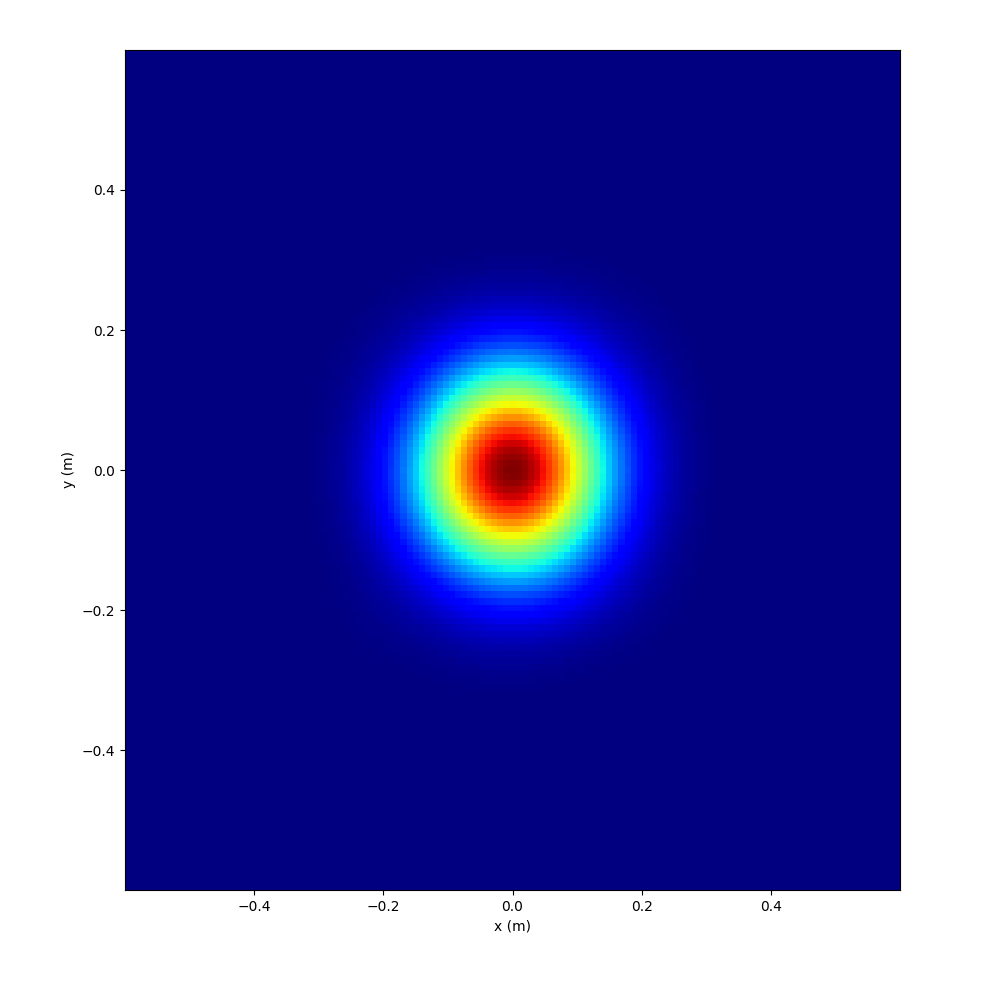

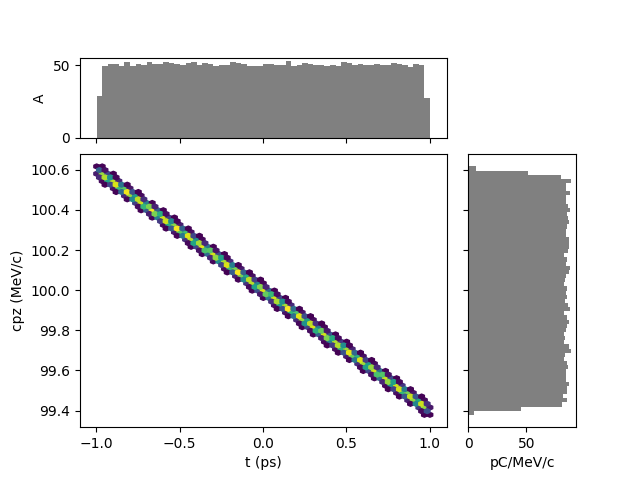

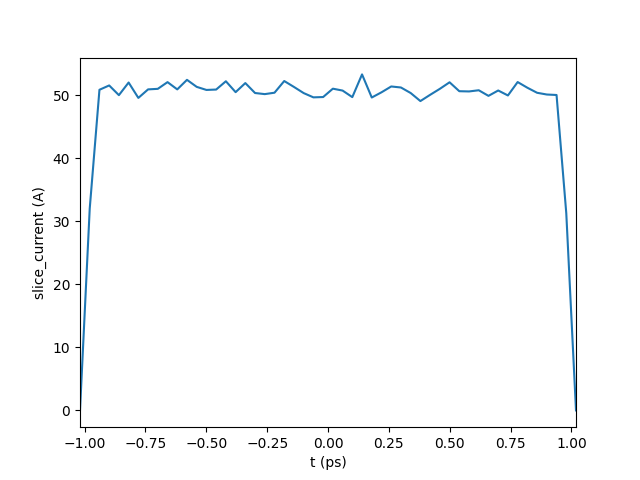

In [10]:
from IPython.display import Image, display
for name in ["screen_xy", "t_cpz", "slices"]:
    display(Image(filename=f"../output/07_beam_analysis_and_plots/{name}.png"))